In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:

np.random.seed(42)

n = 100

data = {
    "Student_ID": range(1, n + 1),
    "Maths": np.random.randint(35, 101, n),
    "Science": np.random.randint(35, 101, n),
    "English": np.random.randint(35, 101, n),
    "Attendance": np.random.randint(50, 101, n),
    "Study_Hours": np.random.randint(1, 9, n),
    "Assignment_Avg": np.random.randint(40, 101, n),
    "Previous_Score": np.random.randint(35, 101, n)
}

df = pd.DataFrame(data)

df["Final_Score"] = (
    df["Maths"] * 0.20 +
    df["Science"] * 0.20 +
    df["English"] * 0.20 +
    df["Attendance"] * 0.10 +
    df["Study_Hours"] * 1.5 +
    df["Assignment_Avg"] * 0.15 +
    df["Previous_Score"] * 0.15
).round(2)

print("Student Dataset Created Successfully!")

df.head()

Student Dataset Created Successfully!


,Student_ID,Maths,Science,English,Attendance,Study_Hours,Assignment_Avg,Previous_Score,Final_Score
0,1,86,39,53,74,3,80,95,73.75
1,2,49,48,82,71,4,58,73,68.55
2,3,95,61,37,71,8,51,35,70.60
3,4,55,43,54,98,4,48,37,58.95
4,5,58,49,58,91,2,46,96,66.40


In [3]:

# Add some missing values for demonstration
df.loc[5, "Maths"] = np.nan
df.loc[10, "Attendance"] = np.nan
df.loc[15, "Assignment_Avg"] = np.nan

# Add a duplicate record
df = pd.concat([df, df.iloc[[0]]], ignore_index=True)

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
Student_ID        0
Maths             1
Science           0
English           0
Attendance        1
Study_Hours       0
Assignment_Avg    1
Previous_Score    0
Final_Score       0
dtype: int64

Duplicate Records:
1


In [4]:

# Remove duplicate records
df = df.drop_duplicates()

# Fill missing numerical values with their column averages
df = df.fillna(df.mean(numeric_only=True))

print("Data Cleaning Completed!")

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nDataset After Cleaning:")
df.head()

Data Cleaning Completed!

Missing Values After Cleaning:
Student_ID        0
Maths             0
Science           0
English           0
Attendance        0
Study_Hours       0
Assignment_Avg    0
Previous_Score    0
Final_Score       0
dtype: int64

Dataset After Cleaning:


,Student_ID,Maths,Science,English,Attendance,Study_Hours,Assignment_Avg,Previous_Score,Final_Score
0,1,86.0,39,53,74.0,3,80.0,95,73.75
1,2,49.0,48,82,71.0,4,58.0,73,68.55
2,3,95.0,61,37,71.0,8,51.0,35,70.60
3,4,55.0,43,54,98.0,4,48.0,37,58.95
4,5,58.0,49,58,91.0,2,46.0,96,66.40


In [5]:

print("Average Student Marks:")
print(df[["Maths", "Science", "English"]].mean())

print("\nHighest Marks:")
print(df[["Maths", "Science", "English"]].max())

print("\nLowest Marks:")
print(df[["Maths", "Science", "English"]].min())

print("\nAverage Attendance:")
print(df["Attendance"].mean())

print("\nAverage Final Score:")
print(df["Final_Score"].mean())

Average Student Marks:
Maths      68.111111
Science    66.210000
English    68.570000
dtype: float64

Highest Marks:
Maths       99.0
Science    100.0
English    100.0
dtype: float64

Lowest Marks:
Maths      35.0
Science    35.0
English    36.0
dtype: float64

Average Attendance:
75.0909090909091

Average Final Score:
74.52100000000002


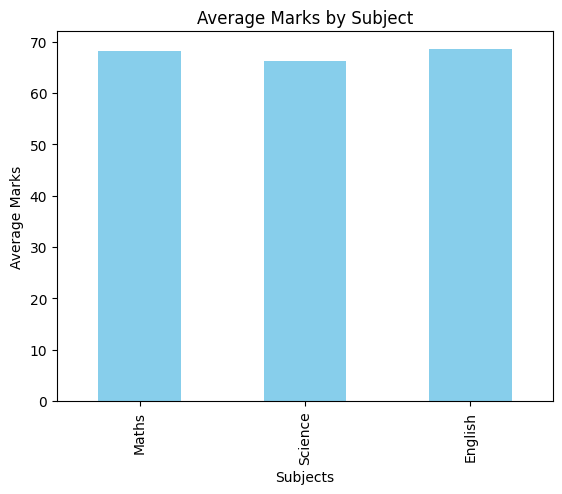

In [6]:

subject_avg = df[["Maths", "Science", "English"]].mean()

subject_avg.plot(kind="bar", color="skyblue")

plt.title("Average Marks by Subject")
plt.xlabel("Subjects")
plt.ylabel("Average Marks")
plt.show()

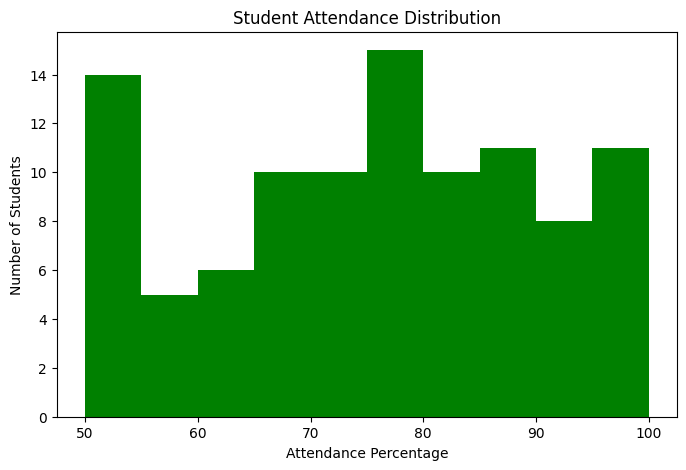

In [7]:

plt.figure(figsize=(8, 5))

plt.hist(df["Attendance"], bins=10, color="green")

plt.title("Student Attendance Distribution")
plt.xlabel("Attendance Percentage")
plt.ylabel("Number of Students")

plt.show()

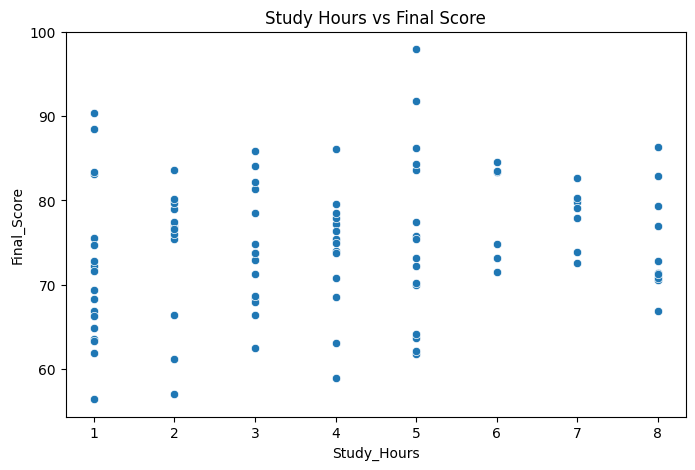

In [8]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Study_Hours",
    y="Final_Score"
)

plt.title("Study Hours vs Final Score")
plt.show()

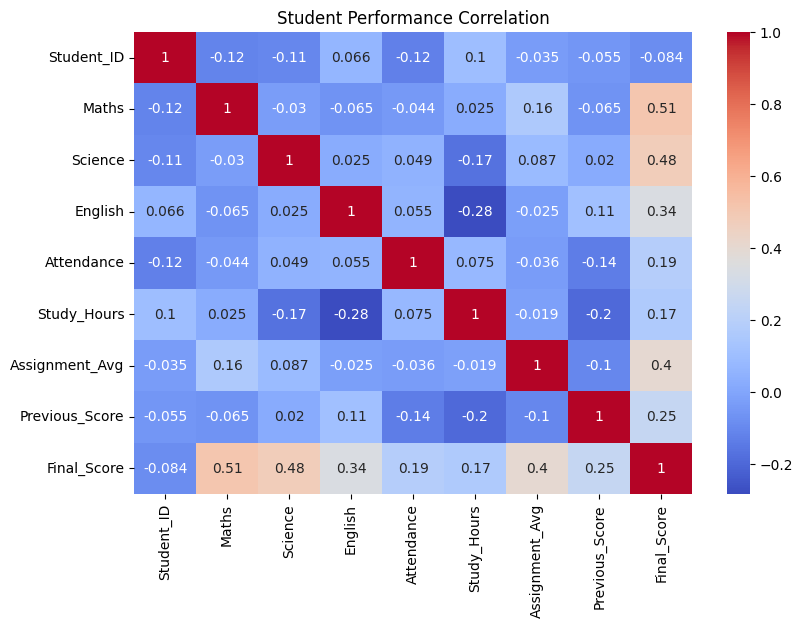

In [9]:

plt.figure(figsize=(9, 6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Student Performance Correlation")
plt.show()

In [10]:

def get_performance(score):
    if score >= 80:
        return "Excellent"
    elif score >= 60:
        return "Good"
    elif score >= 40:
        return "Average"
    else:
        return "Needs Improvement"

df["Performance"] = df["Final_Score"].apply(get_performance)

print("Student Performance Categories:")
print(df["Performance"].value_counts())

Student Performance Categories:
Performance
Good         74
Excellent    23
Average       3
Name: count, dtype: int64


In [11]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Select input columns
X = df[[
    "Maths",
    "Science",
    "English",
    "Attendance",
    "Study_Hours",
    "Assignment_Avg",
    "Previous_Score"
]]

# Select output column
y = df["Final_Score"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create the model
model = RandomForestRegressor(random_state=42)

# Train the model
model.fit(X_train, y_train)

# Predict student scores
predictions = model.predict(X_test)

# Check model performance
print("Mean Absolute Error:",
      mean_absolute_error(y_test, predictions))

print("R2 Score:",
      r2_score(y_test, predictions))

Mean Absolute Error: 3.616299999999992
R2 Score: 0.6306974950540974


In [12]:

result = pd.DataFrame({
    "Actual Score": y_test.values,
    "Predicted Score": predictions.round(2)
})

print(result.head(10))

   Actual Score  Predicted Score
0         62.50            66.17
1         66.90            69.97
2         82.70            74.62
3         79.70            79.77
4         63.10            69.60
5         74.80            70.48
6         83.65            79.06
7         77.45            75.12
8         68.35            71.12
9         73.75            71.96


In [13]:

df.to_csv("student_performance.csv", index=False)

df.to_excel("student_performance.xlsx", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!
